# Investigating phishing websites

## Introduction

- UUID: **593717e6-6b8b-41c3-80ba-fec2b30f373d**
- State: **Published** : demo version with **output**
- Purpose: This playbook supports SOC analysts in investigating **potential phishing websites** by submitting suspicious URLs to **Lookyloo** for analysis.
    - It begins with **initial triage**, querying **MISP** (feeds and cache) and **URLscan** to identify any prior sightings or correlations of the URL.  
    - The URL is then **submitted to Lookyloo**, which performs a full capture and returns analysis results, including a **screenshot**, that are automatically attached to the relevant **MISP event**.  
    - The playbook **enriches** the event with additional context from Lookyloo, such as related URLs, IPs, and hostnames, while applying **threat intelligence curation** to filter out likely false positives.  
    - Finally, the event is **classified and tagged** with appropriate **MISP galaxies and taxonomy tags**, then **shared** with relevant external communities to support broader threat awareness.
- Tags: [ "phishing", "triage" ]
- External resources: **Lookyloo, URLScan, CIRCL MMDB**
- Target audience: **SOC**, **CSIRT**, **CTI**

[![](https://mermaid.ink/img/pako:eNp1lFFv2jAQx7-KZYk3qJoQQsjDpIpNGhKVUKvtYU0fTHIQj-SMbKdthvjuOxvIwsZ4CLm7f3y_s-984LkqgKd8NBplaKWtIGULfANj5VZYiVu2L6Up3cs7rI20YDL04sHgIFHalB0yvqnUe14KbTPu7dLW1VKsoTLOsRGVgeORHQeDDDspWz5lyOhnmvVWi33JMr6gBaWoWAEWcisVMoEFk2jFDjJ-ku9N8LK6MH17Wr6e3IBFhp1iNPpkdXBthpd4L-FKQyVriUK3zGoptl0a-vwl4_MS8h2TG7ZD9Y5Ewh4Xz6uMv15EIYm-SmOVljmBS9wottGqdmQmF9hJe3ynp0CHJTCkp8QrVoHjazO4gf6AomqNNBdgUhHLc7OupWVWsaVSu7ZSqiOgVE6QawA0pbInzhuyMcm-jGoh_UHQn7lVhfT88sw_7j725rRflDgro1vOyS1n3Hf2an6CXOnizzF0JETsPAzeAG1HK33Fc4UWPvpeV-C8oUOrWf5PMKLgg6VmWDfU7L4B1fontaPpiSYkcifswxoKqf8SxCRYrPqeqdtVt6n_30y4lAxn82bLNuuKut9nNjRIXceC34bvoOWm7eXwh046Ny65quuGZqy9ZuBDXoMmtoJugoMLZNyWUIOb3owXsBFNZV2eI0lFY9VzizlPrW5gyLVqtiVP_ZQPebMvhIXPNEpa1J13L5CnB_7B0zC5v0uSWRhNo2gSz6IgGvKW3NPJXRIncTieBVGYRPFxyH8pRSvc38XBeDxNpvE4mCXJJJz45X744ImA9p8G8PF0k_kLbci32lVzJqQqQc9Vg5anQRTPjr8BscqOfw)](https://mermaid.live/edit#pako:eNp1lFFv2jAQx7-KZYk3qJoQQsjDpIpNGhKVUKvtYU0fTHIQj-SMbKdthvjuOxvIwsZ4CLm7f3y_s-984LkqgKd8NBplaKWtIGULfANj5VZYiVu2L6Up3cs7rI20YDL04sHgIFHalB0yvqnUe14KbTPu7dLW1VKsoTLOsRGVgeORHQeDDDspWz5lyOhnmvVWi33JMr6gBaWoWAEWcisVMoEFk2jFDjJ-ku9N8LK6MH17Wr6e3IBFhp1iNPpkdXBthpd4L-FKQyVriUK3zGoptl0a-vwl4_MS8h2TG7ZD9Y5Ewh4Xz6uMv15EIYm-SmOVljmBS9wottGqdmQmF9hJe3ynp0CHJTCkp8QrVoHjazO4gf6AomqNNBdgUhHLc7OupWVWsaVSu7ZSqiOgVE6QawA0pbInzhuyMcm-jGoh_UHQn7lVhfT88sw_7j725rRflDgro1vOyS1n3Hf2an6CXOnizzF0JETsPAzeAG1HK33Fc4UWPvpeV-C8oUOrWf5PMKLgg6VmWDfU7L4B1fontaPpiSYkcifswxoKqf8SxCRYrPqeqdtVt6n_30y4lAxn82bLNuuKut9nNjRIXceC34bvoOWm7eXwh046Ny65quuGZqy9ZuBDXoMmtoJugoMLZNyWUIOb3owXsBFNZV2eI0lFY9VzizlPrW5gyLVqtiVP_ZQPebMvhIXPNEpa1J13L5CnB_7B0zC5v0uSWRhNo2gSz6IgGvKW3NPJXRIncTieBVGYRPFxyH8pRSvc38XBeDxNpvE4mCXJJJz45X744ImA9p8G8PF0k_kLbci32lVzJqQqQc9Vg5anQRTPjr8BscqOfw)

# Playbook

- **Investigating phishing websites**
    - Introduction
- **Preparation**
    - PR:1 Initialise environment
    - PR:2 Load helper functions
    - PR:3 Set helper variables
- **Initial detection and intake**
    - PS:1 Phishing URL
- **Preliminary triage**
    - TR:1 Check if the URL is known within MISP
    - TR:2 Get historical information from URLscan
- **Analysis**
    - AN:1 Submit to Lookyloo
    - AN:2 Get screenshot from Lookyloo
    - AN:3 Record e-mail details
- **Record the phishing threat in MISP**
    - IN:1 Create the MISP event
    - IN:2 Add context to the event
    - IN:3 Add custom context based on your initial analysis
    - IN:4 Add attributes and objects from Lookyloo analysis
    - IN:5 Add URLs and redirects from Lookyloo analysis
    - IN:6 Add IPs from Lookyloo analysis
    - IN:7 Add email object to the MISP event
- **Publish and share**
    - EN:1 Last chance to verify the event title
    - EN:2 Update the target sharing community and publish the event

# Preparation

## PR:1 Initialise environment

The credentials for MISP (**API key**) and other services are loaded from the file `keys.py` in the directory **vault**. A [PyMISP](https://github.com/MISP/PyMISP) object is created to interact with MISP and the active MISP server is displayed. By printing out the server name you know that it's possible to connect to MISP. In case of a problem PyMISP will indicate the error with `PyMISPError: Unable to connect to MISP`.

In [ ]:
# Initialise Python environment
import urllib3
import sys
import requests
import json
import base64
import uuid
from uuid import uuid4
from datetime import date
from pylookyloo import Lookyloo
from pymisp import *
import traceback
import re
import time
from rapidfuzz import fuzz
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image as IPyImage, display
import validators

pr_red = "\033[91m"
pr_green = "\033[92m"
pr_black = "\033[90m"
pr_yellow = "\033[93m"

# Load the credentials
sys.path.insert(0, "../vault/")
from keys import *
if misp_verifycert is False:
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
print(f"{pr_green}Python libraries{pr_black} are loaded and the {pr_green}credentials{pr_black} are read from keys file.")

# PyMISP object and header dictionary for requests outside PyMISP
misp = PyMISP(misp_url, misp_key, misp_verifycert)
misp_headers = {"Authorization": misp_key,  "Content-Type": "application/json", "Accept": "application/json"}
print(f"I will use the MISP server {pr_green}{misp_url}{pr_black} for this playbook.\n\n")

Python libraries are loaded and the credentials are read from keys file.
I will use the MISP server https://phishing-vl.prod.cudeso.be for this playbook.




## PR:2 Load helper functions

Load the **helper functions**. Instead of distributing helper functions as separate Python files this playbook includes all the required code as one code cell. This makes portability of playbooks between instances easier. The downside is that functions defined in this playbook need to be defined again in other playbooks, which is not optimal for code re-use.

In [2]:
def curate_attribute(uuid, value):
    ''' Disable to_ids and tag when the attribute matches a MISP warninglist. '''
    if misp.values_in_warninglist(value):
        attr = misp.get_attribute(uuid, pythonify=True)
        attr.to_ids = 0
        misp.update_attribute(attr)
        t = MISPTag()
        t.name = playbook_config["tag_disable_ids_warninglist"]
        misp.tag(uuid, t, local=True)
        return True
    return False


def likely_good_attribute(attr_uuid, value, asn_number, asn_org):
    ''' Heuristic: disable to_ids for attributes likely pointing to legitimate infra. '''

    good = (
            (asn_number and asn_number in playbook_config.get("likely_good_asn_number", [])) or
            (asn_org and asn_org in playbook_config.get("likely_good_asn_org", []))
        )
    if good:
        attr = misp.get_attribute(attr_uuid, pythonify=True)
        attr.to_ids = 0
        res = misp.update_attribute(attr)
        t = MISPTag()
        t.name = playbook_config["tag_likely_legitimate"]
        misp.tag(attr_uuid, t, local=True)
        log.info("Attribute %s disabled as likely legitimate (ASN=%s, ORG=%s)", attr_uuid, asn_number, asn_org)
        return True
        

def match_target_tag(title, target_tag, threshold=80):
    ''' Guess the phishing target by fuzzy-matching keywords in the page/email title. '''
    title_lower = title.lower()
    for key, keywords in target_tag.items():
        for keyword in keywords:
            score = fuzz.partial_ratio(keyword, title_lower)
            if score >= threshold:
                return key
    return None


def do_ip_enrichment(response_ip, misp_attr, local_tag):
    ''' Add IP enrichment tags: geo + ASN. '''
    r = requests.get(f"{playbook_config['mmdb_url']}{response_ip}", timeout=20)
    data = r.json()

    base = data[0]
    country_name = base.get("country_info", {}).get("Country") or base.get("country_info", {}).get("country")
    iso_code = base.get("country", {}).get("iso_code")

    asn_number = asn_org = None
    for entry in data:
        c = entry.get("country", {})
        if "AutonomousSystemNumber" in c or "AutonomousSystemOrganization" in c:
            asn_number = c.get("AutonomousSystemNumber")
            asn_org = c.get("AutonomousSystemOrganization")
            break

    enrichment = {
        "country": country_name,
        "iso_code": iso_code,
        "asn_number": asn_number,
        "asn_org": asn_org,
    }

    for k, v in enrichment.items():
        if v is None:
            continue
        t = MISPTag()
        t.name = f'{k}:"{str(v).strip()}"'
        misp.tag(misp_attr.uuid, t, local=local_tag)
    return enrichment


def search_misp_cache_feeds(search_value):
    ''' Search MISP caches/feeds for given values (POST as per MISP #7478). '''
    misp_cache_url = f"{misp_url}/feeds/searchCaches/"
    print(f" Search for {search_value}")
    match = False
    feed_hits = []
    
    for value in search_value:
        cache_results = requests.post(misp_cache_url, headers=misp_headers, verify=misp_verifycert, json={"value": value})
        for result in cache_results.json():
            if "Feed" in result:
                match = True
                for match in result["Feed"]["direct_urls"]:
                    entry = {"source": "Feeds", "value": value, "feed_name": result["Feed"]["name"], "match_url": match["url"]}
                    if entry not in feed_hits:
                        feed_hits.append(entry)
    return feed_hits


def pb_get_misp_tags(tags=[], local_tags=[]):
    ''' Build a list of MISPTag objects from two lists (global + local). '''
    misp_tags = []
    for el in tags:
        t = MISPTag()
        t.name = el
        t.local = False
        misp_tags.append(t)

    for el in local_tags:
        t = MISPTag()
        t.name = el
        t.local = True
        misp_tags.append(t)
    return misp_tags


def add_comment_attr(value, comment):
    ''' Add a non-to_ids comment attribute if value is present. '''
    if not value:
        return None
    a = MISPAttribute()
    a.type = "comment"
    a.value = value
    a.to_ids = 0
    a.comment = comment
    return misp.add_attribute(misp_event.uuid, a, pythonify=True)


def escape_for_urlscan(value: str) -> str:
    ''' Backslash-escape Lucene reserved characters for urlscan query strings '''
    _reserved = r'+-=&|><!(){}[]^"~*?:\/'
    chars = ''.join(set(list(_reserved) + ['\\']))
    pattern = '[' + re.escape(chars) + ']'
    return re.sub(pattern, lambda m: '\\' + m.group(0), value)


def _ok(result):
    # works whether result is a MISP object (with .errors) or a dict
    return not getattr(result, "errors", None) and not (isinstance(result, dict) and result.get("errors"))


def add_url_list(kind, fetch_fn, list_key, relation):
    ''' Ingest URLs (or redirects) from a Lookyloo fetch function and attach as MISP attributes. '''
    data = fetch_fn(playbook_results["lookyloo"]["analysis_uuid"])
    urls = data.get("response", {}).get(list_key, []) or []
    ignore = [u.strip().lower() for u in playbook_config.get("ignore_urls", [])]

    for u in urls:
        u_clean = u.strip()
        if any(ig in u_clean.lower() for ig in ignore):
            continue

        attr = MISPAttribute()
        attr.type = "url"
        attr.value = u_clean
        attr.to_ids = 0
        attr.comment = f'{"URLs" if kind=="used" else "Redirects"} {kind} by {playbook_results["url"]}'

        res = misp.add_attribute(misp_event.uuid, attr, pythonify=True)
        print(f" Add URL {pr_green}{u_clean}{pr_black}")

        if _ok(res) and playbook_results["submit_url_object"]:
            playbook_results["correlation_entries"].append(u_clean)
            misp.add_object_reference(playbook_results["submit_url_object"].add_reference(res.uuid, relation))
            print(" Add object reference")
            
print(f"{pr_green}Helper functions loaded{pr_black}.\n\n")

Helper functions loaded.




## PR:3 Set helper variables

Define the **helper variables** for this playbook.

- `lookyloo_url`: Your **Lookyloo** instance.
- `sectors`: Predefined list of sectors.
- `event_tags`: Global and local **tags** to add to a new event.
- `event_title_default_prefix`: Event **title**.
- `tag_disable_ids_warninglist` : How to tag an attribute when it matches the **warninglist** (likely false positive).
- `tag_likely_legitimate` : How to tag an attribute when it's likely **legitimate**.
- `likely_good_asn_number` and `likely_good_asn_org` : List of likely known good ASN numbers and names.
- `ignore_urls` : A list of URLs to be ignored as attributes. Avoid overloading the event with non-relevant attributes.
- `target_tag` : List of tags used when guessing the phishing target.
- `urlscan_url`, `urlscan_size` and `urlscan_replace`: **URLscan** URL, maximum result size and pattern replacement for submitting URLs.
- `mmdb_url`: Used for IP enrichment

In [3]:
playbook_results = {}

playbook_config = {"sectors": {
                                "government": 'misp-galaxy:sector="Government, Administration"',
                                "finance": 'misp-galaxy:sector="Finance"',
                                "insurance": 'misp-galaxy:sector="Insurance"',
                                "water": 'misp-galaxy:sector="Water"',
                                "transport": 'misp-galaxy:sector="Transport"',
                                "telecom": 'misp-galaxy:sector="Telecoms"',
                                "online_market": 'misp-galaxy:sector="Online marketplace"',
                                "logistic": 'misp-galaxy:sector="Logistic"',
                                "energy": 'misp-galaxy:sector="Energy"',
                            },
                   
                   "event_title_default_prefix": "Phishing investigation",
                   "event_tags": pb_get_misp_tags(["tlp:clear", "phishing:report-type=\"manual-reporting\"", 
                                                       "misp-galaxy:mitre-attack-pattern=\"Spearphishing Link - T1192\"", 
                                                       "phishing:state=\"active\"", 
                                                       "circl:incident-classification=\"phishing\"",
                                                       "misp-galaxy:target-information=\"Belgium\"",
                                                       "Phishing"
                                                     ],
                                                  ["workflow:state=\"incomplete\""]),

                   "tag_disable_ids_warninglist": "curation:curated=\"disable_ids_warninglist\"",
                   "tag_likely_legitimate": "curation:curated=\"likely_legitimate\"",
                   "likely_good_asn_number": ["GOOGLE"],
                   "likely_good_asn_org": ["15169"],

                   "ignore_urls": ["https://www.google-analytics.com/", "https://fonts.googleapis.com", "https://fonts.gstatic.com", "/font-awesome-new/webfonts/fa-",
                                   "/js/creative.js", "/js/jquery.", "/js/wow.min.js", "/js/bootstrap.min.js",
                                   "/css/all.css", "/css/creative.css",
                                   "https://www.googletagmanager.com", "https://www.google-analytics.com", "https://region1.google-analytics.com",
                                   ".png", ".jpg", ".gif", ".css",
                                  ],
                    
                   "target_tag": {"vlaanderen": {"vlaanderen", "vlaams"},
                                  "argenta": {"argenta", "argentabank"},
                                  "watergroup": {"water", "watergroep"},
                                  "bnp": {"bnp", "fortis"},
                                  "itsme": {"itsme"},
                                  "cm": {"cm", "christelijkemutualiteit"},
                                 },
                   
                   "urlscan_url" : "https://urlscan.io/api/v1/search",
                   "urlscan_size": 3,
                   "urlscan_replace": ["+", "-", "=", "&&", "||", ">", "<", "!", "(", ")", "{", "}", "[", "]", "^", "~", "*", "?", ":", "/"],

                   "mmdb_url": "https://ip.circl.lu/geolookup/",
                   "lookyloo_url": "https://lookyloo.prod.cudeso.be"
                  }

print(f"{pr_green}Helper variables loaded{pr_black}.\n\n")

Helper variables loaded.




# Initial detection and intake

## PS:1 Phishing URL

This step records the **user input** or the **URL under investigation**. Do not apply defanging and normalise tracking parameters.

In [4]:
# Provide the (phishing) URL to investigate
query = "https://www.misp-project.org/"

# Validate we have a valid URL to investigate
if validators.url(query):
    print(f"The playbook will continue with the investigation of {pr_green}{query}{pr_black}\n\n")
    playbook_results["url"] = query
    playbook_results["correlation_entries"] = [playbook_results["url"]]
else:
    print("URL validation {pr_red}failed{pr_black}.\nCheck that {pr_red}{query}{pr_black} is a valid URL.\n")

The playbook will continue with the investigation of https://www.misp-project.org/




# Preliminary triage

## TR:1 Check if the URL is known within MISP 

In [5]:
# Query MISP feeds and find the correlations
print("Search in MISP.")
result_misp_cache_feeds = search_misp_cache_feeds([playbook_results["url"]])
if len(result_misp_cache_feeds) > 0:
    playbook_results["result_misp_cache_feeds"] = result_misp_cache_feeds
    print(f" Found {pr_green}{len(result_misp_cache_feeds)}{pr_black} entries.")
    for entry in result_misp_cache_feeds:
        print(f"  Match {pr_green}{entry["value"]}{pr_black} in {pr_green}{entry["feed_name"]}{pr_black} {entry["match_url"]}.")
else:
    print(f" {pr_yellow}No results found in MISP{pr_black}.")
print("Finished searching in MISP feeds.")

Search in MISP.
 Search for ['https://www.misp-project.org/']
 Found 1 entries.
  Match https://www.misp-project.org/ in MISP-INTERN https://phishing-vl.prod.cudeso.be/servers/previewEvent/1/47884e26-6e6f-4580-a803-74968e796be2.
Finished searching in MISP feeds.


## TR:2 Get historical information from URLscan

Search in urlscan for https://www.misp-project.org/
 Received URLscan results for https://www.misp-project.org/
Got 3 results.


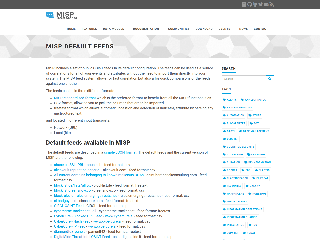

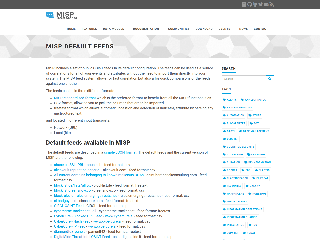

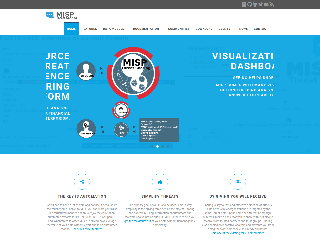

In [6]:
# Search historical scans in URLscan
module_name = "urlscan"
playbook_results[module_name] = {"enrichment": []}

print(f"Search in {pr_green}{module_name}{pr_black} for {playbook_results['url']}")
headers = {"API-Key": urlscan_apikey, "Content-Type": "application/json", "Cache-Control": "no-cache"}
urlscan_url = "{}/?size={}&q=page.url:{}".format(playbook_config["urlscan_url"], playbook_config["urlscan_size"], escape_for_urlscan(playbook_results["url"]))
result = requests.get(urlscan_url, headers=headers)
if result.status_code == 200 and result.json().get("total") > 0:
    print(f" Received URLscan results for {pr_green}{playbook_results["url"]}{pr_black}")
    for el in result.json().get("results", []):
        screenshot_url = el["screenshot"]
        if not screenshot_url:
            continue
        screenshot_data = requests.get(screenshot_url, timeout=30)
        playbook_results[module_name]["enrichment"].append({
            "screenshot": screenshot_url,
            "screenshot_data": screenshot_data.content  # store only bytes!
        })

if len(playbook_results[module_name]["enrichment"]) > 0:
    print(f"Got {pr_green}{len(playbook_results[module_name]["enrichment"])}{pr_black} results.")
    count = 0
    for enrichment in playbook_results[module_name]["enrichment"]:
        if count >= playbook_config["urlscan_size"]:
            break

        image = PILImage.open(BytesIO(enrichment["screenshot_data"]))
        w_percent = 320 / float(image.size[0])
        h_size = int((float(image.size[1]) * float(w_percent)))
        image_resized = image.resize((320, h_size), PILImage.Resampling.LANCZOS)
        display(image_resized)

        count += 1
else:
    print(f"Did not receive results from {pr_red}{module_name}{pr_black}")

# Analysis

## AN:1 Submit to Lookyloo

This step sends the validated URL to **Lookyloo** for analysis.  Lookyloo will visit the URL, render the page, and collect artefacts such as redirects, resources, and network requests. Wait for the crawl to complete. An operational note: the crawls may vary by time, geolocation, and blocklists; re-runs may yield different trees.

In [7]:
lookyloo = Lookyloo(playbook_config["lookyloo_url"], verify=False)
print(f"Created Lookyloo object {pr_green}{playbook_config["lookyloo_url"]}{pr_black}.")

# Lookyloo result
permaurl = lookyloo.submit(url=playbook_results["url"], proxy=None, referer=playbook_results["url"], timezone_id="Europe/Brussels")

match = re.search(r'/tree/([0-9a-fA-F-]{36})', permaurl)
analysis_uuid = match.group(1)
print(f"Lookyloo submit tracked via the UUID: {pr_green}{analysis_uuid}{pr_black}")

# Query Lookyloo until the capture is finished
while True:
    lookyloo_status = lookyloo.get_status(analysis_uuid)
    lookyloo_status_finished = False
    if "status_code" in lookyloo_status:
        if lookyloo_status["status_code"] == 1:
            lookyloo_status_finished = True
        elif lookyloo_status["status_code"] == -1:
            print(f" {pr_red}Unknown capture, exiting{pr_black}")
            break
        elif lookyloo_status["status_code"] == 2:
            print(" Waiting for capture to finish...")
    
    if lookyloo_status_finished:
        print(" Capture is finished!")
        break

    time.sleep(2)

if lookyloo_status_finished:
    print(f"\nLookyloo results are at: {playbook_config["lookyloo_url"]}/tree/{analysis_uuid}")
    playbook_results["lookyloo"] = lookyloo.get_info(analysis_uuid)
    playbook_results["lookyloo"]["analysis_uuid"] = analysis_uuid
    print(f" Title: {pr_green}{playbook_results["lookyloo"]["title"]}{pr_black}")
    print(f" Capture time: {pr_green}{playbook_results["lookyloo"]["capture_time"]}{pr_black}")

Created Lookyloo object https://lookyloo.prod.cudeso.be.
Lookyloo submit tracked via the UUID: db60f7bc-df3f-4715-945b-2bf7944dc78f
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Waiting for capture to finish...
 Capture is finished!

Lookyloo results are at: https://lookyloo.prod.cudeso.be/tree/db60f7bc-df3f-4715-945b-2bf7944dc78f
 Title: MISP Open Source Threat Intelligence Platform & Open Standards For Threat Information Sharing
 Capture time: 2025-10-14T14:24:20.153000+00:00


## AN:2 Get screenshot from Lookyloo

Did our capture return a **screenshot**? Use the screenshot as an **initial check** to verify if the site is still online.

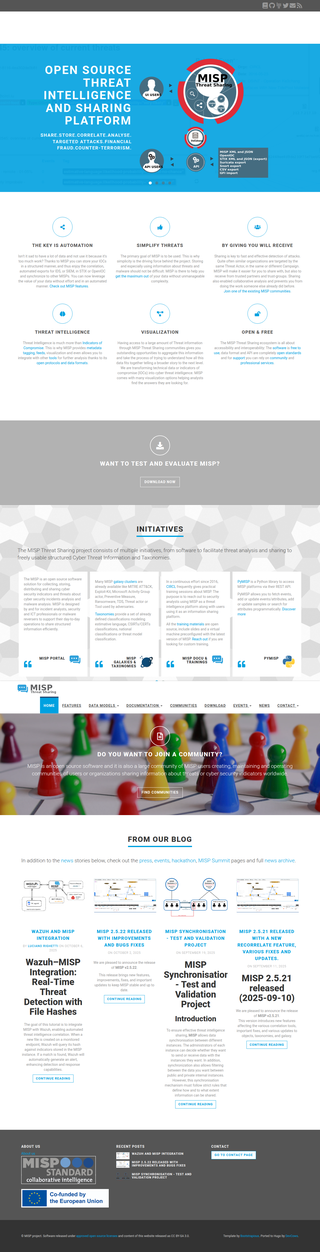

In [8]:
screenshot = lookyloo.get_screenshot(playbook_results["lookyloo"]["analysis_uuid"])

image = PILImage.open(screenshot)
w_percent = 320 / float(image.size[0])
h_size = int((float(image.size[1]) * float(w_percent)))
image_resized = image.resize((320, h_size), PILImage.Resampling.LANCZOS)
display(image_resized)

## AN:3 Record e-mail details 

Add the details how we received the phishing URL via **e-mail**. We use this to create a MISP object to track (and correlate) sender and subject details.

In [10]:
email_subject = "Not the MISP Project"
email_from = "info@not-the-misp-project.org"
email_date = "14-10-2025"

In [11]:
# Create the MISP object
playbook_results["email_object"] = None
email_object = MISPObject("email")
attrs = {
    "subject": email_subject.strip(),
    "from": email_from.strip(),
    "send-date": email_date.strip(),
}
for k, v in attrs.items():
    if v:
        email_object.add_attribute(k, v)
if email_object.attributes:
    print(f"Email object {pr_green}created{pr_black}.")
    playbook_results["email_object"] = email_object
    playbook_results["email_subject"] = email_subject

Email object created.


# Record the phishing threat in MISP

## IN:1 Create the MISP event

Create a new MISP event with 
- Title: Phishing for *victim* - *Lookyloo UUID*
- Distribution: **All communities** (3)
- Threat level: **Low** (3)
- Analysis state: **Initial** (0)

In [12]:
event = MISPEvent()

event_title = f"{playbook_config["event_title_default_prefix"]} for {playbook_results["lookyloo"]["title"].strip().lower()} - {playbook_results["lookyloo"]["analysis_uuid"]}"
event.info = event_title
event.distribution = 3
event.threat_level_id = 3
event.analysis = 0
event.set_date(date.today())
misp_event = misp.add_event(event, pythonify=True)
playbook_results["event"] = misp_event.uuid
print(f"Created MISP event {pr_green}{misp_event.uuid}{pr_black} - {event_title}")

Created MISP event 5d93bac8-d1ca-4a19-af44-c53dc5fe991c - Phishing investigation for misp open source threat intelligence platform & open standards for threat information sharing - db60f7bc-df3f-4715-945b-2bf7944dc78f


## IN:2 Add context to the event

Add the local (`misp_event_local_tags`) and global (`misp_event_global_tags`) tags.

In [13]:
for tag in playbook_config["event_tags"]:
    misp.tag(misp_event.uuid, tag, local=tag.local)
    print(f"Added {pr_green}{tag.name}{pr_black}")

Added tlp:clear
Added phishing:report-type="manual-reporting"
Added misp-galaxy:mitre-attack-pattern="Spearphishing Link - T1192"
Added phishing:state="active"
Added circl:incident-classification="phishing"
Added misp-galaxy:target-information="Belgium"
Added Phishing
Added workflow:state="incomplete"


## IN:3 Add custom context based on your initial analysis

Attempt to **guess the context** based on the email titel or web page title. It first checks the email, then the page title and then the URL.

In [14]:
checks = {
    "e-mail title": (playbook_results["email_subject"]),
    "web page title": (playbook_results["lookyloo"]["title"]),
    "web page URL": (playbook_results["lookyloo"]["url"]),
}

for label, (value) in checks.items():
    result = match_target_tag(value, playbook_config["target_tag"])
    if result:
        print(f"Target tag: based on {label} {value}: {pr_green}phishing:target=\"{result}\"{pr_black} \n")
    else:
        print(f"No context found based on the {label}")

No context found based on the e-mail title
No context found based on the web page title
No context found based on the web page URL


Use the previous cell as input for custom contextualisation. You can now specify the 
- **Victim** via `victim`
- **Sector** by setting `sector` to one of the predefined sectors

In [16]:
# Define victim (from previous analysis)
victim = 'phishing:target="misp"'

# Select active sector
sector = 'misp-galaxy:sector="Technology"'

#"government": 'misp-galaxy:sector="Government, Administration"',
#"finance": 'misp-galaxy:sector="Finance"',
#"insurance": 'misp-galaxy:sector="Insurance"',
#"water": 'misp-galaxy:sector="Water"',
#"transport": 'misp-galaxy:sector="Transport"',
#"telecom": 'misp-galaxy:sector="Telecoms"',
#"online_market": 'misp-galaxy:sector="Online marketplace"',
#"logistic": 'misp-galaxy:sector="Logistic"',
#"energy": 'misp-galaxy:sector="Energy"',

if len(victim) > 0:
    misp.tag(misp_event.uuid, victim, local=False)
    print(f"Victim: {pr_green}{victim}{pr_black}")
if len(sector) > 0:
    misp.tag(misp_event.uuid, sector, local=False)
    print(f"Sector: {pr_green}{sector}{pr_black}")


Victim: phishing:target="misp"
Sector: misp-galaxy:sector="Technology"


## IN:4 Add attributes and objects from Lookyloo analysis

Attach the **Lookyloo analysis results** to the MISP event for record keeping and sharing. It adds
- Lookyloo **attributes and objects**
- Custom attributes such as **title** and capture time
- URL **screenshot**

In [17]:
misp_export = lookyloo.misp_export(playbook_results["lookyloo"]["analysis_uuid"])[0]
playbook_results["submit_url_object"] = None
submit_url_screenshot = None

add_comment_attr(playbook_results["lookyloo"]["title"],        "Web page title")
add_comment_attr(playbook_results["lookyloo"]["capture_time"], "Capture time")

for a in misp_export.get("Attribute", []):
    a = dict(a)                          # shallow copy (avoid mutating export)
    val = a.get("value", "")

    if val == "screenshot_landing_page.png":
        a["comment"] = "screenshot_landing_page.png"
    if playbook_config["lookyloo_url"] in val:
        a["distribution"] = 0
    a.pop("uuid", None)

    try:
        res = misp.add_attribute(misp_event.uuid, a, pythonify=True)
        if not getattr(res, "errors", None):
            if a.get("to_ids") == 1:
                playbook_results["correlation_entries"].append(val)
            if val == "screenshot_landing_page.png":
                submit_url_screenshot = res
            print(f" Added attribute type: {pr_green}{a['type']} - {a['value']}{pr_black}")
    except Exception:
        print(f" Unable to add attribute: {a}")
        traceback.print_exc()


for o in misp_export.get("Object", []):
    if o.get("name") == "file":
        continue

    o = dict(o)
    o.pop("uuid", None)

    try:
        obj = misp.add_object(misp_event.uuid, o, pythonify=True)

        # preserve original behaviour: always add to correlation_entries
        for attr in obj.Attribute:
            add_correlation = True
            if curate_attribute(attr.uuid, attr.value):
                print(f"  Attribute {attr.value} disabled because it matches with warninglist.")
            if attr.type in {"ip-src", "ip-dst", "ip-src|port", "ip-dst|port"}:
                enr = do_ip_enrichment(attr.value, attr, False)
                if enr and likely_good_attribute(attr.uuid, attr.value, enr.get("asn_number"), enr.get("asn_org")):
                    print(f"  Attribute {attr.value} disabled because it is likely linked to a legitimate resource.")
            if add_correlation:
                playbook_results["correlation_entries"].append(attr.value)

        # link objects
        if playbook_results["submit_url_object"]:
            try:
                misp.add_object_reference(playbook_results["submit_url_object"].add_reference(obj.uuid, "related"))
            except Exception:
                traceback.print_exc()

        if o.get("comment") == "Submitted URL":
            playbook_results["submit_url_object"] = obj
            if submit_url_screenshot:
                misp.add_object_reference(playbook_results["submit_url_object"].add_reference(submit_url_screenshot.uuid, "screenshot-of"))

        print(f" Added object type: \033[92m{o['name']}\033[90m")
    except Exception:
        print(f" Unable to add object: {o}")
        traceback.print_exc()

print("Finished adding results")

 Added attribute type: link - https://lookyloo.prod.cudeso.be/tree/db60f7bc-df3f-4715-945b-2bf7944dc78f
 Added attribute type: attachment - screenshot_landing_page.png
 Added object type: url
Finished adding results


## IN:5 Add URLs and redirects from Lookyloo analysis

Add additional URLs and redirects found by Lookyloo during its analysis. These are added as informational attributes (to_ids is set to False) so you can correlate with other events. The additional URLs often represent the **external resources** used by the phishing site. The URLs matching `skip_url` are excluded to avoid exploding the MISP event.

In [18]:
# URLs used on the page
add_url_list(kind="used", fetch_fn=lookyloo.get_urls,      list_key="urls",      relation="uses")
# Redirect chain
add_url_list(kind="redirected", fetch_fn=lookyloo.get_redirects, list_key="redirects", relation="redirects-to")

print("Finished adding results")

 Add URL https://www.misp-project.org/js/front.js
 Add object reference
 Add URL https://cdnjs.cloudflare.com/ajax/libs/waypoints/4.0.1/jquery.waypoints.min.js
 Add object reference
 Add URL https://cdnjs.cloudflare.com/ajax/libs/Counter-Up/1.0/jquery.counterup.min.js
 Add object reference
 Add URL https://cdnjs.cloudflare.com/ajax/libs/jquery-cookie/1.4.1/jquery.cookie.min.js
 Add object reference
 Add URL https://www.misp-project.org/js/owl.carousel.min.js
 Add object reference
 Add URL https://use.fontawesome.com/releases/v5.11.2/webfonts/fa-regular-400.woff2
 Add object reference
 Add URL https://cdnjs.cloudflare.com/ajax/libs/jquery-parallax/1.1.3/jquery-parallax.js
 Add object reference
 Add URL https://use.fontawesome.com/releases/v5.11.2/webfonts/fa-brands-400.woff2
 Add object reference
 Add URL https://code.jquery.com/jquery-3.1.1.min.js
 Add object reference
 Add URL https://www.misp-project.org/
 Add object reference
 Add URL https://use.fontawesome.com/releases/v5.11.2/web

Something went wrong (403): {'saved': False, 'name': 'Could not add Attribute', 'message': 'Could not add Attribute', 'url': '/attributes/add', 'errors': {'value': ['A similar attribute already exists for this event.']}}


 Add URL https://www.misp-project.org/
Finished adding results


## IN:6 Add IPs from Lookyloo analysis

Add IP found by Lookyloo during its analysis, mostly related to the URL under investigation, redirects or additional resources that were included by the phishing site. IP attributes are **enriched** with geo and ASN information. The cell also prevents adding **false positives** by checking the warninglists `curate_attribute` and the list of likely bening attributes (`likely_good_attribute`).

In [19]:
get_ips = lookyloo.get_ips(playbook_results["lookyloo"]["analysis_uuid"])
local_tag = False

if "response" in get_ips and len(get_ips["response"]["ips"]) > 0:
    for response_ip in get_ips["response"]["ips"]:
        if response_ip != "127.0.0.1":
            attr = MISPAttribute()
            attr.type = "ip-dst"
            attr.value = response_ip
            attr.to_ids = 1
            attr.comment = f"IPs used by {playbook_results["url"]}"
    
            result = misp.add_attribute(misp_event.uuid, attr, pythonify=True)
            print(f"Add IP \033[92m{response_ip}\033[90m")
            if not "errors" in result and playbook_results["submit_url_object"]:
                playbook_results["correlation_entries"].append(response_ip)
                misp.add_object_reference(playbook_results["submit_url_object"].add_reference(result.uuid, "resolves-to"))
                print(" Add object reference")
                enrichment_result = do_ip_enrichment(response_ip, result, local_tag)
                if curate_attribute(result.uuid, response_ip):
                    print("  Attribute disabled because it matches with warninglist.")
                elif enrichment_result and likely_good_attribute(result.uuid, response_ip, enrichment_result.get("asn_number", False), enrichment_result.get("asn_org", False)):
                    print("  Attribute disabled because it is likely linked to a legitimate resource.")
print("Finished adding results")

Add IP 172.67.142.245
 Add object reference
  Attribute disabled because it matches with warninglist.
Add IP 142.251.36.10
 Add object reference
  Attribute disabled because it matches with warninglist.
Add IP 142.250.179.163
 Add object reference
  Attribute disabled because it matches with warninglist.
Add IP 104.18.10.207
 Add object reference
  Attribute disabled because it matches with warninglist.
Add IP 151.101.66.137
 Add object reference
  Attribute disabled because it matches with warninglist.
Add IP 104.17.24.14
 Add object reference
  Attribute disabled because it matches with warninglist.
Add IP 185.194.93.128
 Add object reference
Finished adding results


## IN:7 Add email object to the MISP event

Finally, if we defined an e-mail object before we also add it to the event. This object allows you to pivot to other phishing URLs with the same sender or the same e-mail subject.

In [20]:
if playbook_results["email_object"]:
    result = misp.add_object(misp_event.uuid, playbook_results["email_object"], pythonify=True)
    if not "errors" in result:
        print(f"Add {pr_green}email object{pr_black}")
        if playbook_results["submit_url_object"]:
            misp.add_object_reference(result.add_reference(playbook_results["submit_url_object"].uuid, "contains"))

Add email object


# Publish and share

## EN:1 Last chance to verify the event title

Before you publish the event (and share it with the other MISP communities), you get a last chance to verify the event title is correct. Based on the previous indicators you might want to change the title of the MISP event to something more meaningful.

In [22]:
print("Current event title: \033[92m{}\033[90m".format(misp_event.info))
print("Change the title?")

Current event title: Phishing investigation for misp open source threat intelligence platform & open standards for threat information sharing - db60f7bc-df3f-4715-945b-2bf7944dc78f
Change the title?


In [23]:
new_event_title = ""

if len(new_event_title) > 0:
    misp_event.info= new_event_title
    print(misp.update_event(misp_event, pythonify=True))

## EN:2 Update the target sharing community and publish the event

In this final step, the playbook prepares the event for sharing and publication across connected MISP communities.

This cell:
- Updates the **workflow state** (`workflow:state`) to *complete*, indicating that the curation process is finished.  
- Adds a **routing tag** (`release-requested`) to signal your Edge MISP instance that the event is ready for redistribution.  
- Defines the **target communities** (`curation:target`) with which the event will be shared, based on your organisation’s sharing policy.

Once executed, the event will be published and made available to the selected MISP communities for collaboration and further analysis.


In [21]:
misp.untag(misp_event.uuid, "workflow:state=\"incomplete\"")
misp.tag(misp_event.uuid, "workflow:todo=\"release-requested\"", local=True)
misp.tag(misp_event.uuid, "workflow:state=\"complete\"", local=True)

#misp.tag(misp_event.uuid, "curation:target=\"FIRST\"", local=True)
#misp.tag(misp_event.uuid, "curation:target=\"CIRCL-MISPPRIV\"", local=True)
#print(misp.publish(misp_event.uuid))

{'saved': True,
 'success': True,
 'name': 'Local tag workflow:state="complete"(163) successfully attached to Event(75).',
 'message': 'Local tag workflow:state="complete"(163) successfully attached to Event(75).',
 'url': '/tags/attachTagToObject'}